Every simulation starts from one thing: numbers that look uniformly random on $(0, 1)$. This page
turns those uniforms into coin tosses, binomials, exponentials, Poissons, betas, normals and
geometrics, then uses them to simulate a single-server queue and compare it with the textbook
formulas, and finishes by estimating areas with random points.

Python and R use different random number generators, so the two versions draw different numbers
even from the same seed. The formulas they are checked against are the same.

To run it yourself you need only base R; there is nothing to install. `set.seed(123)` fixes the
random numbers, so a top-to-bottom run gives the numbers shown here.

In [1]:
set.seed(123)
options(repr.plot.width = 6, repr.plot.height = 4.2, repr.plot.res = 100)

## From uniforms to coin tosses

A toss is heads when $U < p$. With $p = 0.5$, toss a coin 1,000 times and track the running share of
heads. **Predict:** after how many tosses does the share stay within 0.05 of one half?

share after 1000 tosses: 0.507 | last toss outside 0.45-0.55: 43 


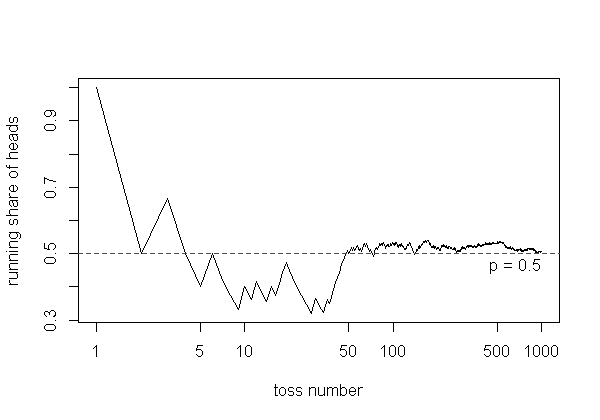

In [2]:
U <- runif(1000)
heads <- as.integer(U < 0.5)
running <- cumsum(heads) / (1:1000)
plot(1:1000, running, type = "l", log = "x", xlab = "toss number", ylab = "running share of heads")
abline(h = 0.5, col = "gray30", lty = 2)
text(1000, 0.49, "p = 0.5", adj = c(1, 1))    # a text label: legend() boxes come out mis-sized in Jupyter's R kernel
outside <- which(abs(running - 0.5) > 0.05)
cat("share after 1000 tosses:", running[1000], "| last toss outside 0.45-0.55:", max(outside), "\n")
# alt: On a log scale of toss number, the running share of heads starts at 1, dips to about 0.32 near toss 30, stays within 0.05 of the dashed line at 0.5 from toss 44 on, and ends at 0.507 after 1,000 tosses.

Each toss is a Bernoulli($p$) variable, and a sum of $n$ of them is Binomial($n$, $p$). With
$n = 1000$ and $p = 0.2$, do this 5,000 times and compare with the built-in binomial generator.
**Predict** the mean and variance.

In [3]:
X_built <- rowSums(matrix(runif(5000 * 1000) < 0.2, nrow = 5000))
X_rbinom <- rbinom(5000, 1000, 0.2)
cat(sprintf("built from uniforms: mean %.2f, variance %.1f\n", mean(X_built), var(X_built)))
cat(sprintf("R's rbinom:          mean %.2f, variance %.1f\n", mean(X_rbinom), var(X_rbinom)))
cat("formulas: np =", 1000 * 0.2, "| np(1 - p) =", 1000 * 0.2 * 0.8, "\n")

built from uniforms: mean 200.13, variance 161.4


R's rbinom:          mean 200.08, variance 162.9


formulas: np = 200 | np(1 - p) = 160 


Any discrete distribution works the same way. Let $P(X=1) = 0.35$, $P(X=2) = 0.15$, $P(X=3) = 0.4$
and $P(X=4) = 0.1$. Stack the probabilities into the cumulative values 0.35, 0.5, 0.9, 1 and return
the first $x$ whose cumulative value reaches $U$.

In [4]:
values <- 1:4
Fx <- cumsum(c(0.35, 0.15, 0.40, 0.10))
X <- values[findInterval(runif(10000), Fx, left.open = TRUE) + 1]
cat("cumulative:", Fx, "\n")
round(prop.table(table(X)), 3)

cumulative: 0.35 0.5 0.9 1 


X
    1     2     3     4 
0.354 0.148 0.398 0.101 

## Inverse transform for continuous variables

The same trick for a continuous variable: solve $F(X) = U$ for $X$. Take the density
$f(x) = 2.5\,x^{1.5}$ on $[0, 1]$. Its CDF is $F(x) = x^{2.5}$, so $X = U^{1/2.5} = U^{0.4}$. The exact
mean is $\int_0^1 x \cdot 2.5\,x^{1.5}\,dx = 2.5/3.5 = 5/7$. **Predict:** is a draw more likely to be
above or below 0.5?

In [5]:
X <- runif(10000)^0.4
cat("mean:", round(mean(X), 4), "| 5/7 =", round(5 / 7, 4), "| share above 0.5:", mean(X > 0.5), "\n")

mean: 0.7152 | 5/7 = 0.7143 | share above 0.5: 0.8236 


The exponential with rate $\lambda$ has $F(x) = 1 - e^{-\lambda x}$, so $X = -\ln(1 - U)/\lambda$.
Since $1 - U$ is also uniform, $X = -\ln(U)/\lambda$ works as well.

In [6]:
lam <- 1
X <- -log(runif(10000)) / lam
cat(sprintf("built: mean %.3f, sd %.3f | rexp: mean %.3f | formula: 1/lambda = %.1f\n", mean(X), sd(X), mean(rexp(10000, rate = lam)), 1 / lam))

built: mean 0.999, sd 0.988 | rexp: mean 0.983 | formula: 1/lambda = 1.0


## Transformations: sums and counts of exponentials

A sum of $n$ independent Exponential($\lambda$) variables is Gamma($n$, $\lambda$), with mean
$n/\lambda$ and variance $n/\lambda^2$. Here $n = 20$, and each row of the array is one gamma draw.

In [7]:
n <- 20
X <- rowSums(matrix(-log(runif(10000 * n)) / lam, ncol = n))
cat(sprintf("built gamma: mean %.2f, variance %.2f | formula: %.1f, %.1f\n", mean(X), var(X), n / lam, n / lam^2))

built gamma: mean 20.03, variance 20.15 | formula: 20.0, 20.0


Turn it around: count how many exponential inter-arrival times fit into one unit of time. With
arrival rate $\lambda = 2$, that count is Poisson(2). The loop adds gaps until the clock passes 1.
**Predict** the mean and the variance of the count.

In [8]:
lam <- 2
counts <- replicate(10000, {
  clock <- -log(runif(1)) / lam
  k <- 0
  while (clock < 1) {
    k <- k + 1
    clock <- clock - log(runif(1)) / lam
  }
  k
})
cat(sprintf("built Poisson: mean %.3f, variance %.3f | rpois: mean %.3f\n", mean(counts), var(counts), mean(rpois(10000, lam))))

built Poisson: mean 1.991, variance 2.020 | rpois: mean 1.996


## Acceptance-rejection

Some CDFs cannot be inverted by hand. Beta(2, 4) has density $f(x) = 20x(1-x)^3$ on $[0, 1]$.
Draw a candidate $U_1$ uniformly, and keep it with probability $f(U_1)/c$, where $c$ is the largest
value of $f$. Calculus puts the peak at $x = 1/4$, so $c = 135/64$. Find it numerically first, from the
function on a fine grid.

In [9]:
grid <- seq(0, 1, length.out = 10001)
f_grid <- 20 * grid * (1 - grid)^3
c_max <- max(f_grid)    # (not "c", which would hide R's c() function from a reader)
cat("grid max:", round(c_max, 5), "at x =", grid[which.max(f_grid)], "| 135/64 =", 135 / 64, "\n")

grid max: 2.10938 at x = 0.25 | 135/64 = 2.109375 


Draw 20,000 candidate pairs $(U_1, U_2)$ and keep $U_1$ whenever $U_2 \le f(U_1)/c$. **Predict:**
what share of candidates is kept? (The area under $f$ is 1, and the box it sits in has area $c$.)

In [10]:
U1 <- runif(20000); U2 <- runif(20000)
kept <- U1[U2 <= 20 * U1 * (1 - U1)^3 / c_max]
cat(sprintf("kept %d of 20000 (%.3f) | 1/c = %.3f\n", length(kept), length(kept) / 20000, 1 / c_max))
cat(sprintf("mean of kept: %.4f | Beta(2,4) mean 2/6 = %.4f | rbeta mean: %.4f\n", mean(kept), 2 / 6, mean(rbeta(20000, 2, 4))))

kept 9490 of 20000 (0.474) | 1/c = 0.474


mean of kept: 0.3360 | Beta(2,4) mean 2/6 = 0.3333 | rbeta mean: 0.3336


## Normals with the Box-Muller method

Two independent uniforms give two independent standard normals:

$$\begin{aligned}
Z_1 &= \sqrt{-2\ln U_1}\,\cos(2\pi U_2) \\
Z_2 &= \sqrt{-2\ln U_1}\,\sin(2\pi U_2)
\end{aligned}$$

It is exact but slow, because of the square root, logarithm, sine and cosine. Below, $Z_1$ is
drawn against the built-in normal generator and the standard normal density.

Z1: mean -0.033, sd 1.001 | Z2: mean -0.012, sd 0.981 | correlation 0.004


share within 1.96 of 0: 0.951 (Box-Muller), 0.949 (rnorm)


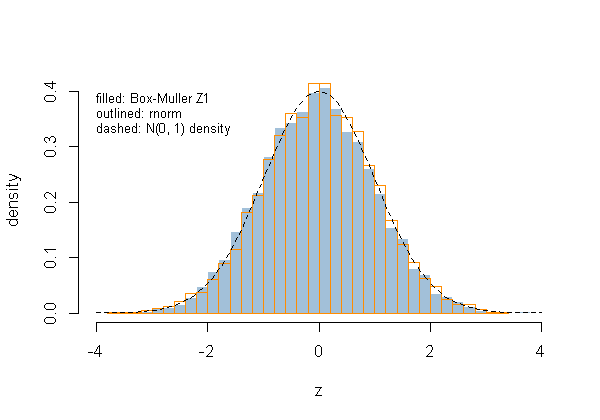

In [11]:
U1 <- runif(5000); U2 <- runif(5000)
Z1 <- sqrt(-2 * log(U1)) * cos(2 * pi * U2)
Z2 <- sqrt(-2 * log(U1)) * sin(2 * pi * U2)
cat(sprintf("Z1: mean %.3f, sd %.3f | Z2: mean %.3f, sd %.3f | correlation %.3f\n", mean(Z1), sd(Z1), mean(Z2), sd(Z2), cor(Z1, Z2)))
Z3 <- rnorm(5000)
hist(Z1, breaks = 40, freq = FALSE, col = adjustcolor("steelblue", 0.5), border = "white",
     xlim = c(-4, 4), main = "", xlab = "z", ylab = "density")
hist(Z3, breaks = 40, freq = FALSE, col = NA, border = "darkorange", add = TRUE)
curve(dnorm(x), from = -4, to = 4, lty = 2, lwd = 1.5, add = TRUE)
text(-4, 0.4, "filled: Box-Muller Z1\noutlined: rnorm\ndashed: N(0, 1) density", adj = c(0, 1), cex = 0.8)
cat("share within 1.96 of 0:", round(mean(abs(Z1) < 1.96), 3), "(Box-Muller),", round(mean(abs(Z3) < 1.96), 3), "(rnorm)\n")
# alt: The filled Box-Muller histogram and the outlined rnorm histogram both follow the dashed bell curve of the standard normal, peaking near 0.4 at z = 0, and about 95% of each sample lies within 1.96 of zero.

## Counting trials: geometric and negative binomial

Repeat Bernoulli($p$) trials until the first success; $K$ is the number of failures plus the one
success. With $p = 0.2$, the mean is $1/p = 5$.

R's `rgeom` counts only the failures, so add 1 to compare.

In [12]:
p <- 0.2
K <- replicate(10000, {
  k <- 1
  while (runif(1) > p) k <- k + 1
  k
})
cat(sprintf("built geometric: mean %.3f | rgeom + 1: %.3f | 1/p = %.1f\n", mean(K), mean(rgeom(10000, p) + 1), 1 / p))

built geometric: mean 4.982 | rgeom + 1: 4.994 | 1/p = 5.0


Keep going until $r = 2$ successes and count all the trials: negative binomial, mean $r/p = 10$.

R's `rnbinom` counts only the failures, so add $r$ to compare.

In [13]:
r <- 2
trials <- replicate(10000, {
  successes <- 0
  k <- 0
  while (successes < r) {
    k <- k + 1
    if (runif(1) <= p) successes <- successes + 1
  }
  k
})
cat(sprintf("built: mean %.3f | rnbinom + r: %.3f | r/p = %.1f\n", mean(trials), mean(rnbinom(10000, r, p) + r), r / p))

built: mean 10.057 | rnbinom + r: 9.875 | r/p = 10.0


## Queueing metrics

The usual measures of a queue, which carry over to most simulations:

- $L$: average number of jobs in the system; $L_q$: average number waiting in the queue
- $W$: average time a job spends in the system; $W_q$: average time waiting in the queue
- utilisation (share of time the server is busy) and throughput (jobs finished per unit time)
- the distributions of waiting time, system size and queue size, not just their averages

For an M/M/1 queue (exponential arrivals at rate $\lambda$, one exponential server at rate $\mu$,
$\rho = \lambda/\mu < 1$) the averages have formulas. A busy period (from an arrival at an empty
system until it next empties) also has a mean:

$$\begin{aligned}
L &= \frac{\rho}{1 - \rho} \\
W &= \frac{L}{\lambda} = \frac{1}{\mu - \lambda} \\
\text{mean busy period} &= \frac{1}{\mu - \lambda}
\end{aligned}$$

With $\lambda = 0.3$ and $\mu = 1$: $\rho = 0.3$, $L = 0.3/0.7 \approx 0.4286$, and $W$ and the mean
busy period are both $1/0.7 \approx 1.4286$.

## An M/M/1 queue, simulated

Simulate it event by event. With $n$ jobs present, the next event comes after an exponential time at
rate $\lambda + \mu$ (or $\lambda$ if the system is empty), and it is an arrival with probability
$\lambda/(\lambda + \mu)$. Between events, add $n \times$ (time elapsed) to a running area; the area
divided by the clock is the time-average $L$. Run to time 500, ten times.
**Predict:** will all ten estimates of $L$ land within 0.1 of 0.4286?

In [14]:
lam <- 0.3; mu <- 1
rho <- lam / mu
horizon <- 500; reps <- 10
L_sim <- busy_share <- busy_period <- numeric(reps)
for (rep in 1:reps) {
  clock <- 0; n_jobs <- 0; area <- 0; busy <- 0; n_busy_periods <- 0
  while (clock < horizon) {
    rate <- if (n_jobs > 0) lam + mu else lam
    dt <- rexp(1, rate)
    area <- area + n_jobs * dt
    if (n_jobs > 0) busy <- busy + dt
    clock <- clock + dt
    if (n_jobs == 0) {
      n_jobs <- 1; n_busy_periods <- n_busy_periods + 1    # an arrival starts a busy period
    } else if (runif(1) < lam / rate) {
      n_jobs <- n_jobs + 1                                 # an arrival
    } else {
      n_jobs <- n_jobs - 1                                 # a departure
    }
  }
  L_sim[rep] <- area / clock
  busy_share[rep] <- busy / clock
  busy_period[rep] <- busy / n_busy_periods
}
cat("L from each run:", round(L_sim, 3), "\n")

L from each run: 0.358 0.478 0.416 0.509 0.263 0.269 0.539 0.383 0.299 0.512 


Now the averages over the ten runs beside the formulas. $W$ comes from Little's law, $W = L/\lambda$,
applied to each run.

In [15]:
round(data.frame(
  "formula" = c(rho / (1 - rho), 1 / (mu - lam), rho, 1 / (mu - lam)),
  "simulated (mean of 10)" = c(mean(L_sim), mean(L_sim) / lam, mean(busy_share), mean(busy_period)),
  "sd across runs" = c(sd(L_sim), sd(L_sim) / lam, sd(busy_share), sd(busy_period)),
  row.names = c("L", "W", "utilisation", "mean busy period"), check.names = FALSE
), 4)

,formula,simulated (mean of 10),sd across runs
,<dbl>,<dbl>,<dbl>
L,0.4286,0.4028,0.1043
W,1.4286,1.3426,0.3478
utilisation,0.3000,0.2846,0.0563
mean busy period,1.4286,1.3395,0.2372


## Monte Carlo integration

Estimate $\int_{0.01}^{1} x^{-0.5}\,dx$ (exactly $2(1 - 0.1) = 1.8$) by throwing points into a box and
counting the share that land under the curve. The box spans $x$ from 0.01 to 1 and $y$ from 0 to the
function's largest value on that range, found on a grid as before. **Predict:** with 1,000 points,
how far from 1.8 will the estimate be?

box height 10.00 | hits 189 of 1000 | estimate 1.8711 | exact 1.8


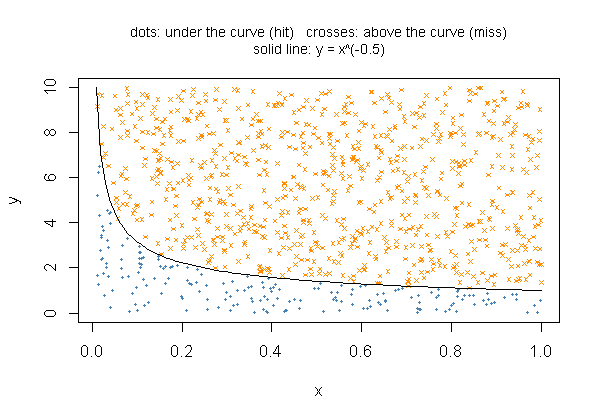

In [16]:
a <- 0.01; b <- 1
height <- max(seq(a, b, length.out = 10001)^-0.5)
x <- runif(1000, a, b)
y <- runif(1000, 0, height)
hit <- y < x^-0.5
cat(sprintf("box height %.2f | hits %d of 1000 | estimate %.4f | exact 1.8\n", height, sum(hit), (b - a) * height * mean(hit)))
plot(x[hit], y[hit], pch = 16, cex = 0.4, col = "steelblue", xlim = c(a, b), ylim = c(0, height), xlab = "x", ylab = "y")
points(x[!hit], y[!hit], pch = 4, cex = 0.5, col = "darkorange")
curve(x^-0.5, from = a, to = b, add = TRUE)
title(main = "dots: under the curve (hit)   crosses: above the curve (miss)\nsolid line: y = x^(-0.5)", cex.main = 0.85, font.main = 1)
# alt: Of 1,000 random points in the box from x = 0.01 to 1 and y = 0 to 10, the 189 dots under the steep curve y = x^-0.5 sit in a thin band along the bottom and a spike at the far left, while the crosses above the curve fill the rest of the box.

The same idea for a semicircle: $\int_{-1}^{1}\sqrt{1 - x^2}\,dx$ is half the area of the unit
circle, $\pi/2$. The box height is the function's largest value on the range, rounded up. Use a
million points this time.

In [17]:
a <- -1; b <- 1
height <- ceiling(max(sqrt(1 - seq(a, b, length.out = 2001)^2)))
x <- runif(1e6, a, b)
y <- runif(1e6, 0, height)
estimate <- (b - a) * height * mean(y < sqrt(1 - x^2))
cat(sprintf("box height %g | estimate %.5f | pi/2 = %.5f\n", height, estimate, pi / 2))

box height 1 | estimate 1.57155 | pi/2 = 1.57080


## Questions

- The ten simulated values of $L$ are spread out even though the model never changes. Would running
  one simulation to time 5,000 or ten to time 500 give you a better estimate, and why?
- Raise $\lambda$ to 0.9 in the queue and rerun. What happens to $L$ and to the spread across runs?
- Acceptance-rejection threw away about half its candidates. What would happen to that share if $c$
  were set larger than the true maximum, and would the kept values still be Beta(2, 4)?